In [23]:
import pandas as pd
import warnings
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.neighbors import KNeighborsClassifier
from sklearn import metrics
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score

# k-Nearest Neighbors(KNN)
This approach is based on a very simple and logical idea: observations of the same class should resemble each other.
- in our digit examples: this definitely makes sense.But what does this concretely mean? and how can we tell a computer when things resemble each other?

Main concept: K-NN means that similar data points belong to the same class and are located close to each other in the feature space.

# problem setting
Gonna use the familiar digits dataset for our k-NN implementation


image data shape (1797, 64)
label data shape (1797,)


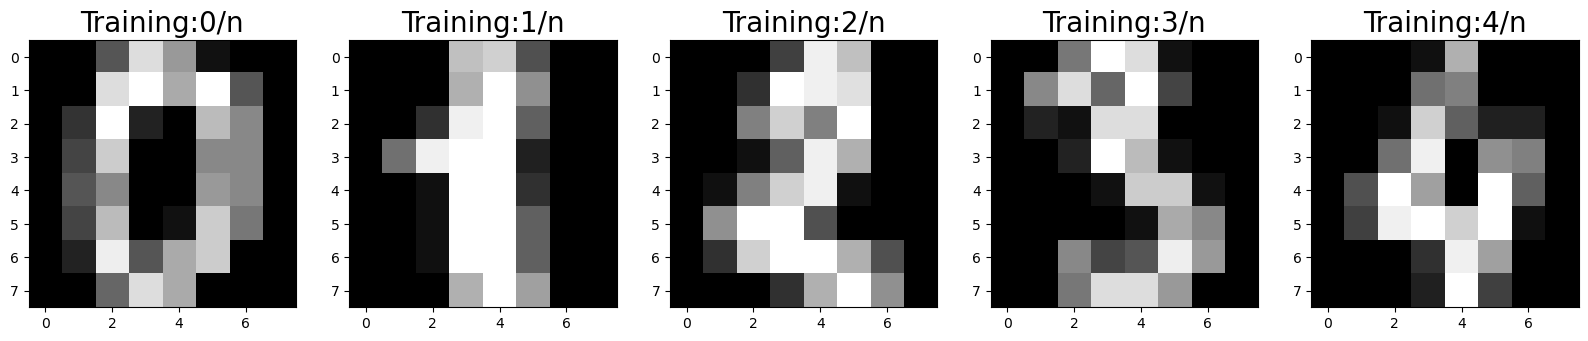

In [24]:
digits=datasets.load_digits()
print("image data shape",digits.data.shape)
print("label data shape",digits.target.shape)
plt.figure(figsize=(20,4))
for index,(image,label) in enumerate(zip(digits.data[0:5],digits.target[0:5])):
    plt.subplot(1,5,index+1)
    plt.imshow(np.reshape(image,(8,8)),cmap=plt.cm.gray)
    plt.title('Training:%i/n'% label,fontsize=20)
plt.show()

In [25]:
X_train,X_test,y_train,y_test = train_test_split(digits.data,digits.target,test_size=0.25,random_state=0)

The most common distance metric used is the EUclidean distance,but other metrics like manhattan or minkowski distance can also be used depending on the problem.

The nearest neighbors vote on which class we should predict for the query point.Different voting schemes are possible,But the most straightforward approach is MAJORITY voting: The class that is represented the most among the k nearest becomes the final prediction.
- imagine there are a lot of points mixed with blue red and green...and we want to predict a random point and want to classify the class of that point...if the k=5 and we find 3 blue points,1 red and 1 green...the the prediction would be blue since it has the majority vote

# Model estimation
We will create a 9-nearest neighbors classifier and fit it to our training data.
- the choice of k=9 is arbitrary for now.we will explore how to choose the optimal k value later

In [26]:
model = KNeighborsClassifier(n_neighbors=9)
model.fit(X_train,y_train)

KNeighborsClassifier(n_neighbors=9)

We can make prediction in different ways:
- for a single observation(one image)
- for multiple observations at once
- for all observation in our test set

In [27]:
# need to reshape single observation using .reshape(1,-1) to match the expected input format for scikit learn
print(model.predict(X_test[0].reshape(1,-1))) # for one observation
print(model.predict(X_test[0:10])) # for multiple observation
print(model.predict(X_test)) # the entire test set

[2]
[2 8 2 6 6 7 1 9 8 5]
[2 8 2 6 6 7 1 9 8 5 2 8 6 6 6 6 1 0 5 8 8 7 8 4 7 5 4 9 2 9 4 7 6 8 9 4 3
 1 0 1 8 6 7 7 1 0 7 6 2 1 9 6 7 9 0 0 5 1 6 3 0 2 3 4 1 9 7 6 9 1 8 3 5 1
 2 8 2 2 9 7 2 3 6 0 5 3 7 5 1 2 9 9 3 1 7 7 4 8 5 8 5 5 2 5 9 0 7 1 4 7 3
 4 8 9 7 9 8 2 6 5 2 5 3 4 1 7 0 6 1 5 9 9 9 5 9 9 5 7 5 6 2 8 6 9 6 1 5 1
 5 9 9 1 5 3 6 1 8 9 7 7 6 7 6 5 6 0 8 1 9 3 6 1 0 4 1 6 3 8 6 7 4 9 6 3 0
 3 3 3 0 7 7 5 7 8 0 7 8 9 6 4 5 0 1 4 6 4 3 3 0 9 5 9 2 1 4 2 1 6 8 9 2 4
 9 3 7 6 2 3 3 1 6 9 3 6 3 2 2 0 7 6 1 1 9 7 2 7 8 5 5 7 5 2 3 7 2 7 5 5 7
 0 9 1 6 5 9 7 4 3 8 0 3 6 4 6 3 2 6 8 8 8 4 6 7 5 2 4 5 3 2 4 6 9 4 5 4 3
 4 6 2 9 0 1 7 2 0 9 6 0 4 2 0 7 5 8 5 7 8 2 8 4 3 7 2 6 9 1 5 1 0 8 2 1 9
 5 6 8 2 7 2 1 5 1 6 4 5 0 9 4 1 1 7 0 8 9 0 5 4 3 8 8 6 5 3 4 4 4 8 8 7 0
 9 6 3 5 2 3 0 8 3 3 1 3 3 0 0 4 6 0 7 7 6 2 0 4 4 2 3 7 1 9 8 6 8 5 6 2 2
 3 1 7 7 8 0 3 3 2 1 5 5 9 1 3 7 0 0 7 0 4 5 9 3 3 4 3 1 8 9 8 3 6 2 1 6 2
 1 7 5 5 1 9]


# Model evaluation

In [28]:
print(accuracy_score(y_test,model.predict(X_test)))
print(precision_score(y_test,model.predict(X_test),average="weighted"))

0.9777777777777777
0.9787938425447269


try different values of k and observe the pattern.Check what happens when k is small(1) versus when k is large.

best_k: 1 with accuracy 0.9911111111111112


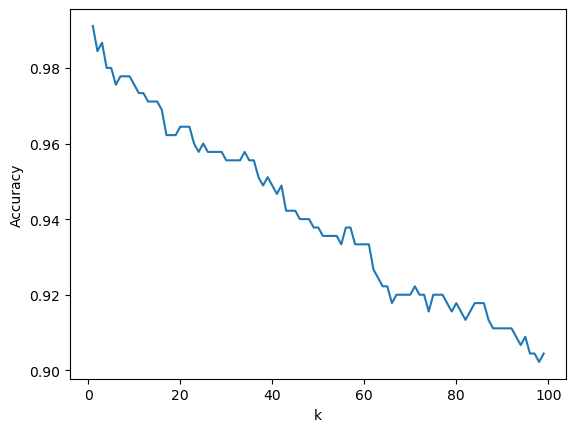

In [29]:
k_values = range(1,100)
accuracies = []
for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train,y_train)
    accuracies.append(accuracy_score(y_test,model.predict(X_test)))
best_k = k_values[np.argmax(accuracies)]
print("best_k:",best_k,"with accuracy",max(accuracies))
plt.plot(k_values,accuracies)
plt.xlabel('k')
plt.ylabel("Accuracy")
plt.show()

we observe a clear downward trend: The highest accuracy is reached at very small values of k(k=1 gives about 0.991) after which accuracy gradually decreases to about 0.90 at k 99.The decline is not perfectly linear. it is small and somewhat bumpy for low k and becomes steadier for larger k.This is expected behavior.
- the higher the value of k, the more neighbors vote on the final label
- as k increases we include neighbors which are further away from our qquery point and therefore more likely to belong to dufferent class

important constraint: K must be a positive integer and cannot exceed the number of training samples.

Key insight: There a trade off with k- too small and the model is sensitive to noise (overfitting). to large and the model become generalized(underfitting)
- the digits dataset is clean and its classes are well separated, which is why even k = 1 performs very well here. On noiser data a somewhat larger k usually works better

# Visualizing the effect of k
to really understand what k does,lets return to simple 2d dataset.

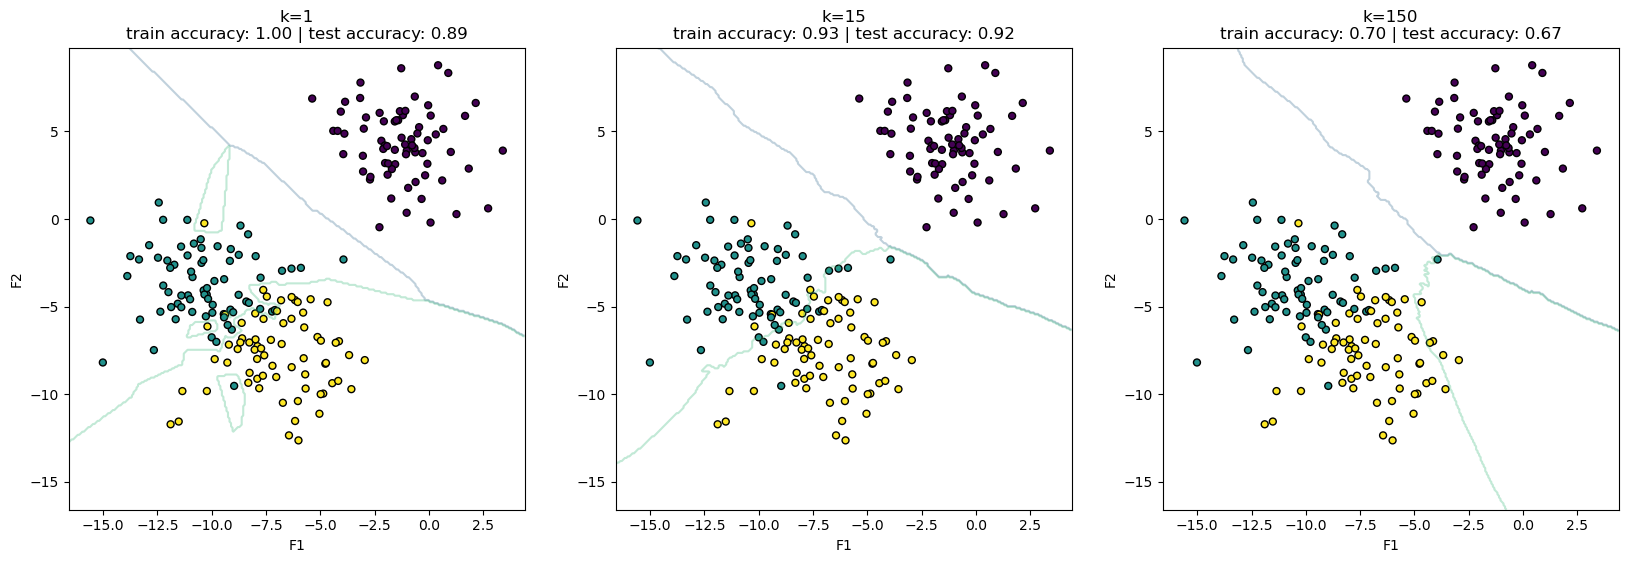

In [30]:
X_blobs,y_blobs = make_blobs(n_samples=300,centers=3,cluster_std=2.0,random_state=1)
Xb_train,Xb_test,yb_train,yb_test=train_test_split(X_blobs,y_blobs,test_size=0.3,random_state=0)
xx,yy=np.meshgrid(np.linspace(X_blobs[:,0].min()-1,X_blobs[:,0].max()+1,300),np.linspace(X_blobs[:,0].min()-1,X_blobs[:,1].max()+1,300))
grid=np.c_[xx.ravel(),yy.ravel()]
fig, axes=plt.subplots(1,3,figsize=(20,6))
for ax,k in zip(axes,[1,15,150]):
    model=KNeighborsClassifier(n_neighbors=k)
    model.fit(Xb_train,yb_train)
    z=model.predict(grid).reshape(xx.shape)
    ax.contour(xx,yy,z,levels=[-0.5,0.5,1.5,2.5],alpha=0.3,cmap='viridis')
    ax.scatter(Xb_train[:,0],Xb_train[:,1],c=yb_train,cmap="viridis",edgecolor = "k",s=25)
    ax.set_title('k=%i\ntrain accuracy: %.2f | test accuracy: %.2f' % (k,accuracy_score(yb_train,model.predict(Xb_train)),accuracy_score(yb_test,model.predict(Xb_test))))
    ax.set_xlabel('F1')
    ax.set_ylabel('F2')
plt.show()

- k(1) the decision boundary is very jagged and forms small "islands" around individual. Every training point is its own nearest neighbor, so the training accuracy is perfect 1.00,But the test accuracy is clearly lower(0.89).The model follows the noise in the training data. This is overfitting
- k = 15: the boundary is smooth and follows the general shape of the classes. Training and test accuracy are both high and close together(0.93 and 0.92)
- k = 150 each vote now involves about 70% of all the training points so the class that is simply most common in a large area wins.The boundary no longer follows the data and both training and test accuracy drop shaply (0.70 and 0.67)...this is underfitting

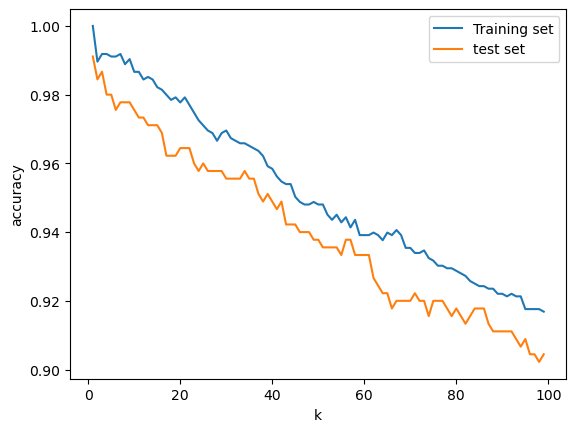

In [31]:
train_accuracies = []
test_accuracies = []
for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train,y_train)
    test_accuracies.append(accuracy_score(y_test,model.predict(X_test)))
    train_accuracies.append(accuracy_score(y_train,model.predict(X_train)))
plt.plot(k_values,train_accuracies,label="Training set")
plt.plot(k_values,test_accuracies,label="test set")
plt.xlabel('k')
plt.ylabel('accuracy')
plt.legend()
plt.show()

at k =1, the training accuracy is exactly 1.0...every training image is its own nearest neighbor,so the model cant get it wrong.This is why training accuracy is useless for choosing k. it would always point to k =1

# Precision and other classification metrics

In [32]:
print(classification_report(y_test,model.predict(X_test)))

              precision    recall  f1-score   support

           0       0.95      1.00      0.97        37
           1       0.79      0.86      0.82        43
           2       0.90      0.86      0.88        44
           3       0.91      0.93      0.92        45
           4       0.97      0.87      0.92        38
           5       0.93      0.90      0.91        48
           6       0.95      1.00      0.97        52
           7       0.86      1.00      0.92        48
           8       0.97      0.73      0.83        48
           9       0.86      0.89      0.88        47

    accuracy                           0.90       450
   macro avg       0.91      0.90      0.90       450
weighted avg       0.91      0.90      0.90       450



- precision measures the proportion of positive predicitons that were actually correct(true positive/(true positive + false positive))

best_k: 1 with precision 0.9912519272278754


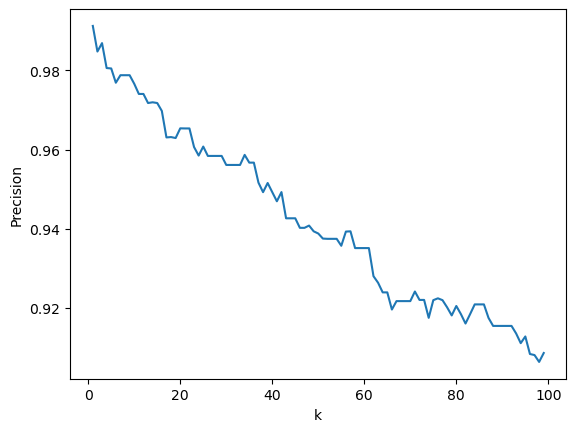

In [33]:
precisions = []
for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train,y_train)
    precisions.append(precision_score(y_test,model.predict(X_test),average="weighted"))
best_k = k_values[np.argmax(precisions)]
print("best_k:",best_k,"with precision",max(precisions))
plt.plot(k_values,precisions)
plt.xlabel('k')
plt.ylabel("Precision")
plt.show()

Here its also the same precisions is highest when k is small and lowest when k is 99...this is expected behavior as k grows...
- the votes of distant neighbors from other classes increasingly cause false positives

# Confusion matrix

Text(0.5, 155.72222222222217, 'predicted label')

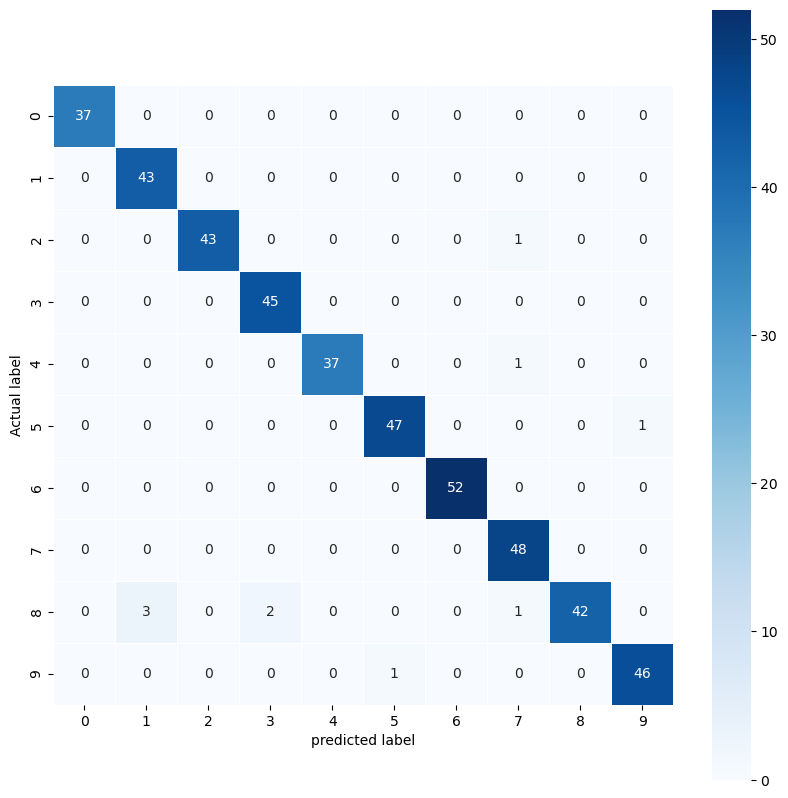

In [34]:
import seaborn as sns
model = KNeighborsClassifier(n_neighbors=9)
model.fit(X_train,y_train)
predictions = model.predict(X_test)
cm = metrics.confusion_matrix(y_test,predictions)
plt.figure(figsize=(10,10))
sns.heatmap(cm,annot=True,fmt="d",linewidths=.5,square=True,cmap="Blues")
plt.ylabel("Actual label")
plt.xlabel("predicted label")


The confusion matrix indicates that we have a really good model
- strong digonal: High numbers along the diagonal indicate many correct pred
- few off digonal values: only 10 of the 450 images were missclassified
- overall pattern : most digits classes (0,1,3,6,7) are predicted without a single error

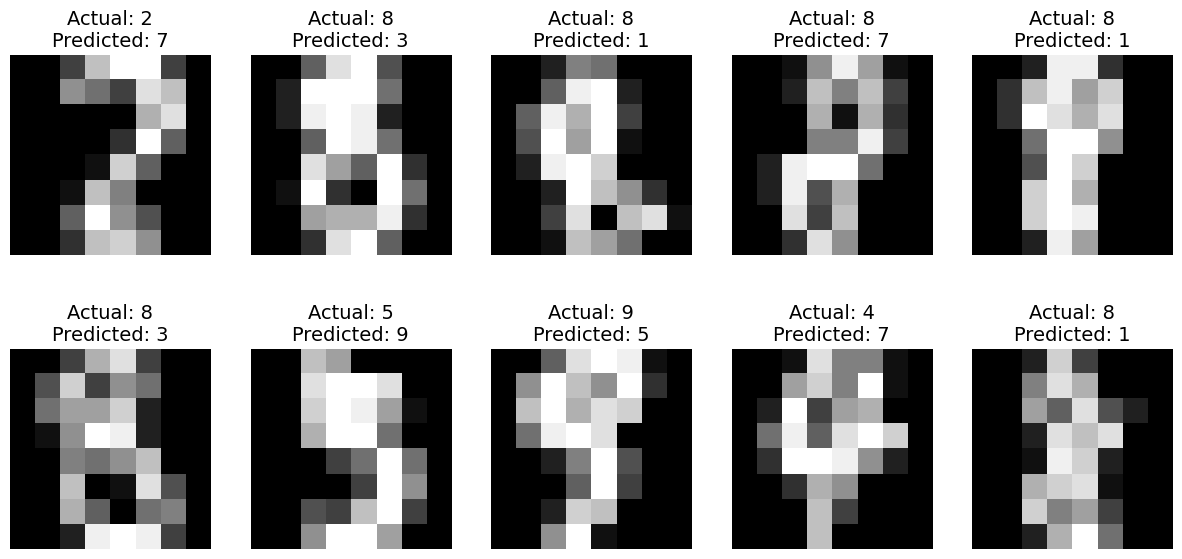

In [35]:
# taking closer look at the wrong mistakes cuz the missclassification is very low(10)...its better to look
wrong = np.where(predictions != y_test)[0]

fig, axes = plt.subplots(2, 5, figsize=(15, 7))
for ax, i in zip(axes.ravel(), wrong):
    ax.imshow(np.reshape(X_test[i], (8,8)), cmap=plt.cm.gray)
    ax.set_title('Actual: %i\nPredicted: %i' % (y_test[i], predictions[i]), fontsize=14)
    ax.axis('off')
plt.show()

In [36]:
# comparing knn logistic regression and decision trees

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

accuracies_log, precisions_log = [], []
accuracies_tree, precisions_tree = [], []
accuracies_knn, precisions_knn = [], []

with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=ConvergenceWarning)
    for solver in ['lbfgs', 'saga', 'newton-cg']:
        for max_iter in [10, 100, 1000, 10000]:
            logisticRegr = LogisticRegression(max_iter=max_iter, solver=solver)
            logisticRegr.fit(X_train, y_train)
            pred = logisticRegr.predict(X_test)
            accuracies_log.append(accuracy_score(y_test, pred))
            precisions_log.append(precision_score(y_test, pred, average='weighted'))

for x in range(1, 31):
    model = DecisionTreeClassifier(max_depth=x, random_state=0)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    accuracies_tree.append(accuracy_score(y_test, pred))
    precisions_tree.append(precision_score(y_test, pred, average='weighted', zero_division=0))

for k in k_values:
    neigh = KNeighborsClassifier(n_neighbors=k)
    neigh.fit(X_train, y_train)
    pred = neigh.predict(X_test)
    accuracies_knn.append(accuracy_score(y_test, pred))
    precisions_knn.append(precision_score(y_test, pred, average='weighted'))

print('Best accuracy  - Logistic regression: %.4f | Decision tree: %.4f | k-NN: %.4f'
      % (max(accuracies_log), max(accuracies_tree), max(accuracies_knn)))
print('Best precision - Logistic regression: %.4f | Decision tree: %.4f | k-NN: %.4f'
      % (max(precisions_log), max(precisions_tree), max(precisions_knn)))

Best accuracy  - Logistic regression: 0.9667 | Decision tree: 0.8444 | k-NN: 0.9911
Best precision - Logistic regression: 0.9669 | Decision tree: 0.8489 | k-NN: 0.9913
